# Task 2 · Operation Inversion: coach's reference solution

**Task.** A frozen neural network, saved as TorchScript in `model.pt`, maps 10 numbers `x0 … x9` to one number `y`. `data.csv` has 1000 rows of `x0 … x9` and the model's output `y`. Then one of the ten input columns was overwritten with `0.0`. Recover that column.

- Changing the model's weights is forbidden. You may only use it: forward passes and gradients.
- Metric: the MSE between your answer and the true column. Score = (MSE_baseline − MSE) / (MSE_baseline − MSE_best) · 100, clipped to [0, 100], with MSE_baseline ≈ 0.968 (answering all zeros) and MSE_best ≈ 0.0045.
- Submit `submission.csv` with the columns `subtaskID` (always 1), `datapointID` (0 … 999) and `answer`, together with your code.

> **Practice data.** `data/inversion_practice/` is a replica built by the coach. It is **not** the real task data: the real model and the real hidden column are different. Only the practice folder has `true_column.csv`, so you can score yourself.

**Plan.** (1) Adam with lr 0.1 on the missing column only, from 0, sum loss, 500 steps: about 98 points in about a second. (2) Every row is a 1-D equation f_i(z) = y_i, so a grid of 2001 values shows **all** its roots. About a third of the rows have two, and the residual cannot tell which one is right. Choose with a prior learned from the other 9 columns: about 98.5 with a plain regression, about 99 with EM.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import torch

torch.set_num_threads(1)  # thousands of tiny forward passes: one thread is fastest, and the machine is shared

DATA_DIR = Path("../data/inversion_practice")  # the practice replica; point this at the real task files later
if not DATA_DIR.exists():  # e.g. Colab: model.pt and data.csv uploaded to the Files panel, next to the notebook
    DATA_DIR = Path(".")

In [2]:
# the loading code given in the task (only the paths are prefixed with DATA_DIR);
# newer torch versions warn that torch.jit is deprecated: it still works
df = pd.read_csv(f"{DATA_DIR}/data.csv")
y = df["y"].values.astype("float32")
X = df.drop(columns="y").values.astype("float32")
model = torch.jit.load(f"{DATA_DIR}/model.pt")
model.eval()
X_t = torch.from_numpy(X)
y_t = torch.from_numpy(y)
with torch.no_grad():
    pred = model(X_t).squeeze()
print("X", tuple(X_t.shape), " y", tuple(y_t.shape), " model output", tuple(pred.shape))
print(f"MSE between y and the model's output with the zeroed column: {((pred - y_t) ** 2).mean():.3f}")

X (1000, 10)  y (1000,)  model output (1000,)
MSE between y and the model's output with the zeroed column: 1.708


/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


## The TorchScript gotcha (torch 2.x)

A scripted model specialises itself on its **first** call. If that call runs with gradients on while the parameters require grad, `torch.no_grad()` no longer stops it from building autograd graphs (wasted time and memory in the grid search below), and `torch.inference_mode()` crashes outright. The given loading code happens to make its first call under `no_grad`, so it is safe until somebody reorders the cells. Freezing the parameters fixes it in every order. `model.requires_grad_(False)` is not supported for ScriptModules, so freeze them one by one. This changes no weight, and gradients with respect to the input still flow.

In [3]:
fresh = torch.jit.load(f"{DATA_DIR}/model.pt")  # a second copy, only for this demonstration
fresh.eval()
fresh(X_t)  # its FIRST call runs with gradients on (a sanity check or a first gradient step would do this)
with torch.no_grad():
    print("first call with gradients, then under no_grad: output requires grad =", fresh(X_t).requires_grad)
for p in fresh.parameters():
    p.requires_grad_(False)
with torch.no_grad():
    print("after freezing the parameters:                  output requires grad =", fresh(X_t).requires_grad)

for p in model.parameters():  # and the same for the model we actually use
    p.requires_grad_(False)

first call with gradients, then under no_grad: output requires grad = True
after freezing the parameters:                  output requires grad = False


In [4]:
zero_cols = (X_t == 0).all(dim=0)  # True for a column that is exactly 0.0 in every row
k = int(zero_cols.nonzero()[0])
N = len(X_t)
print(f"all-zero columns: {zero_cols.nonzero().flatten().tolist()}  ->  the missing column is x{k}")

all-zero columns: [3]  ->  the missing column is x3


In [5]:
def predict(z):
    # model output (N,) when column k is replaced by z (N,); the other 9 columns stay exactly as given
    X_z = torch.cat([X_t[:, :k], z[:, None], X_t[:, k + 1:]], dim=1)
    # reshape(-1) turns the output into shape (N,), whether the model returns (N, 1) or (N,);
    # without it, (N, 1) - (N,) would silently broadcast to (N, N)
    return model(X_z).reshape(-1)

In [6]:
truth_path = DATA_DIR / "true_column.csv"
if truth_path.exists():  # only the practice replica has the true column
    truth = pd.read_csv(truth_path)["x_true"].values
else:
    truth = None  # the real task: no scores, but every other cell still runs
results = {}


def score(answer, name):
    if truth is None:
        print(f"{name}: no true_column.csv (real task): score not available")
        return
    mse = np.mean((answer - truth) ** 2)
    results[name] = {"MSE": mse, "score": np.clip((0.968 - mse) / (0.968 - 0.0045) * 100, 0, 100)}
    print(f"{name}: MSE {mse:.4f}, score {results[name]['score']:.1f}")


score(np.zeros(N), "all zeros (baseline)")

all zeros (baseline): MSE 0.9671, score 0.1


## 1. Adam on the missing column only

- **Adam, lr 0.1.** Adam moves every row by about lr per step whatever its slope, and the values to find are about N(0, 1), so 0.1 covers the range in tens of steps. lr 1e-3 cannot get further than about 0.5 in 500 steps (MSE 0.43); lr 1.0 jumps into the basin of the wrong root.
- **Sum, not mean.** The rows are independent: with the sum, each z_i gets its own full gradient. For Adam it makes no difference (it is invariant to the loss scale); plain SGD with the mean barely moves.
- **Start at 0.** That is the mean of the column. Each row then descends into the root whose basin contains 0, usually the root closest to 0. Starting at 0 is an implicit prior.

In [7]:
z = torch.zeros(N, requires_grad=True)
opt = torch.optim.Adam([z], lr=0.1)  # only z is optimised; the model's weights are frozen
for step in range(500):
    opt.zero_grad()
    loss = ((predict(z) - y_t) ** 2).sum()  # forward + loss
    loss.backward()
    opt.step()
answer_adam = z.detach().numpy().copy()
score(answer_adam, "Adam lr 0.1, 500 steps from 0")

Adam lr 0.1, 500 steps from 0: MSE 0.0236, score 98.0


In [8]:
with torch.no_grad():
    residual = (predict(torch.from_numpy(answer_adam)) - y_t).abs().numpy()
print(f"rows not solved (|residual| > 1e-3): {(residual > 1e-3).sum()}")
if truth is not None:  # this check needs the true column: a coach-only diagnostic
    error = np.abs(answer_adam - truth)
    print(f"rows solved exactly but WRONG (|residual| < 1e-4, |error| > 0.1): {((residual < 1e-4) & (error > 0.1)).sum()}")

rows not solved (|residual| > 1e-3): 14
rows solved exactly but WRONG (|residual| < 1e-4, |error| > 0.1): 14


The second kind is invisible to any residual check: those rows have another exact solution, and gradient descent found the wrong one.

## 2. Look at every value: a grid for all rows at once

One unknown per row means a 1-D search: 2001 values in [−5, 5] for all 1000 rows is 2 million forward rows, under a second without gradients. The other columns are about N(0, 1), so [−5, 5] covers any plausible value.

In [9]:
grid = torch.linspace(-5, 5, 2001)
h = grid[1] - grid[0]  # the grid spacing, 0.005
with torch.no_grad():
    columns = []
    for g in grid:  # put the same value g into every row and run the model once
        columns.append(predict(g.expand(N)) - y_t)
    D = torch.stack(columns, dim=1)  # D[i, j] = f_i(grid[j]) - y_i, shape (1000, 2001)

# a root lies between grid[j] and grid[j + 1] when D changes sign there
sign_change = (D[:, :-1] > 0) != (D[:, 1:] > 0)  # shape (1000, 2000)
rows, j = sign_change.nonzero(as_tuple=True)  # one entry per root: its row and its grid interval
left, right = D[rows, j], D[rows, j + 1]
root = grid[j] + h * left / (left - right)  # where the straight line between the two grid points crosses 0
slope = (right - left) / h  # f'(root), needed by the prior below
roots = pd.DataFrame({"row": rows.numpy(), "root": root.double().numpy(), "slope": slope.double().numpy()})

n_roots = np.bincount(roots["row"], minlength=N)  # the number of roots of each row
counts = np.bincount(np.minimum(n_roots, 3), minlength=4)  # rows with 0, 1, 2, and 3 or more roots
print(f"rows with 0 / 1 / 2 / 3+ roots: {counts.tolist()}")
print(f"ambiguous rows (2+ exact solutions): {(n_roots >= 2).sum()}")

rows with 0 / 1 / 2 / 3+ roots: [0, 669, 330, 1]
ambiguous rows (2+ exact solutions): 331


In [10]:
closest_point = D.abs().argmin(dim=1)  # per row: the grid index where f comes closest to y
fallback = grid[closest_point].double().numpy()  # kept for rows without a root


def fill(per_row):
    # per_row: a Series indexed by row -> a full answer vector (rows without a root keep the fallback)
    answer = fallback.copy()
    answer[per_row.index] = per_row.values
    return answer


score(fallback, "grid, argmin |f - y| (no selection rule)")

idx = roots["root"].abs().groupby(roots["row"]).idxmin()  # per row: the index of its root closest to 0
closest = roots.loc[idx].set_index("row")["root"]
answer_closest = fill(closest)
score(answer_closest, "all roots, the one closest to 0")
print(f"rows where Adam did not end on the root closest to 0: {(np.abs(answer_adam - answer_closest) > 1e-2).sum()}")

grid, argmin |f - y| (no selection rule): MSE 2.1591, score 0.0
all roots, the one closest to 0: MSE 0.0212, score 98.3
rows where Adam did not end on the root closest to 0: 25


The plain grid argmin is biased, not random: argmin |f − y| prefers the root where the curve is flattest, because a grid point lands closer to y there. Here that is often the far root on the negative side (141 rows end below −3): 201 of the 331 ambiguous rows go wrong, and they carry the whole MSE of 2.16 (the single-root rows add about 1e-6). That is why it scores worse than submitting zeros. The search finds the candidates; the selection rule decides the score.

## 3. A prior from the other 9 columns

If the columns are correlated, the other 9 predict the missing one. On the rows with exactly **one** root, that root is the answer, so they are labelled data for a linear regression. Then weigh each root of an ambiguous row by prior(r) / |f′(r)|. That is Bayes' rule for y = f(x): where f is flat, a wider range of x maps onto the same y, so that root collects more prior mass.

In [11]:
from sklearn.linear_model import LinearRegression

others = np.delete(X, k, axis=1)  # the 9 known columns
unique = n_roots == 1
reg = LinearRegression().fit(others[unique], answer_closest[unique])
prior_mean = reg.predict(others)
prior_sd = np.std(answer_closest[unique] - prior_mean[unique])
names = [f"x{i}" for i in range(10) if i != k]
print("regression coefficients:", "  ".join(f"{n} {c:+.2f}" for n, c in zip(names, reg.coef_)))
print(f"prior sd {prior_sd:.3f}  (R^2 on the single-root rows {reg.score(others[unique], answer_closest[unique]):.2f})")

regression coefficients: x0 -0.03  x1 +0.42  x2 +0.04  x4 -0.26  x5 +0.26  x6 +0.00  x7 -0.07  x8 +0.05  x9 -0.06
prior sd 0.692  (R^2 on the single-root rows 0.42)


In [12]:
roots["prior_mean"] = prior_mean[roots["row"]]  # each root gets the prior mean of its row
z_score = (roots["root"] - roots["prior_mean"]) / prior_sd
prior = np.exp(-0.5 * z_score ** 2)  # Gaussian prior density, up to a constant
roots["weight"] = prior / roots["slope"].abs().clip(lower=1e-3)  # Bayes: prior(r) / |f'(r)|

idx = roots["weight"].groupby(roots["row"]).idxmax()  # per row: the index of its root with the largest weight
most_likely = roots.loc[idx].set_index("row")["root"]
score(fill(most_likely), "regression prior, most likely root")

weighted_sum = (roots["weight"] * roots["root"]).groupby(roots["row"]).sum()
total_weight = roots["weight"].groupby(roots["row"]).sum()
posterior_mean = weighted_sum / total_weight
score(fill(posterior_mean), "regression prior, posterior mean")

regression prior, most likely root: MSE 0.0200, score 98.4
regression prior, posterior mean: MSE 0.0192, score 98.5


**Why the posterior mean wins on MSE.** Take two roots 0.5 apart with equal weight. Submitting either one costs 0.125 in expectation; submitting the midpoint costs 0.0625. The posterior mean minimises the expected squared error, while the most likely root only minimises the chance of being wrong.

**Selection bias.** The regression only sees single-root rows, and which rows are ambiguous depends on the other columns. On this replica x4 gets −0.26 although the generator made it independent of x3: x4 only enters y through an x3·x4 term, and that term decides which rows have a second root. EM fixes this by fitting the prior on **all** rows, letting each ambiguous row count with fractional weights on its roots.

## 4. EM: learn the prior from all rows

In [13]:
A = np.c_[others, np.ones(N)]  # 9 known columns + an intercept
beta = np.zeros(A.shape[1])  # start from the N(0, 1) prior
sd = 1.0
for it in range(50):
    # E-step: each root's posterior weight under the current prior; each row's weights sum to 1
    prior_mu = (A @ beta)[roots["row"]]
    prior = np.exp(-0.5 * ((roots["root"] - prior_mu) / sd) ** 2)
    w = prior / roots["slope"].abs().clip(lower=1e-3)
    w = w / w.groupby(roots["row"]).transform("sum")
    mean = (w * roots["root"]).groupby(roots["row"]).sum()  # posterior mean of every row that has a root
    var = (w * roots["root"] ** 2).groupby(roots["row"]).sum() - mean ** 2
    # M-step: regress the posterior means on the other columns; the spread includes each row's own uncertainty
    beta = np.linalg.lstsq(A[mean.index], mean.values, rcond=None)[0]
    sd = np.sqrt(np.mean(var + (mean - A[mean.index] @ beta) ** 2))
print("EM coefficients:", "  ".join(f"{n} {c:+.2f}" for n, c in zip(names, beta[:-1])))
print(f"prior sd {sd:.3f}")
answer_em = fill(mean)
score(answer_em, "EM prior, posterior mean")

EM coefficients: x0 -0.03  x1 +0.50  x2 +0.03  x4 -0.01  x5 +0.33  x6 -0.03  x7 -0.06  x8 +0.03  x9 -0.04
prior sd 0.763
EM prior, posterior mean: MSE 0.0145, score 99.0


One ambiguous row where "closest to 0" picked the wrong root:

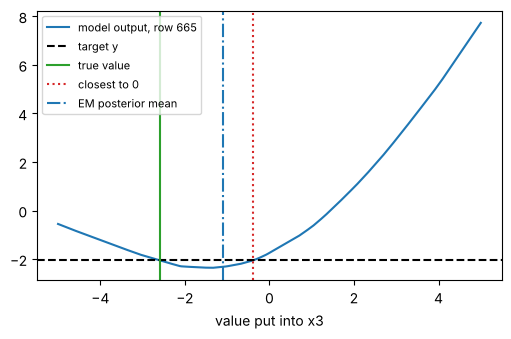

  root  slope
-2.592 -0.496
-0.389  0.559


In [14]:
import matplotlib.pyplot as plt

if truth is not None:
    row = int(np.argmax(np.abs(answer_closest - truth)))  # the row where "closest to 0" is most wrong
else:
    row = int(np.argmax(np.abs(answer_closest - answer_em)))  # real task: where the two rules disagree most
plt.figure(figsize=(6, 3.5))
plt.plot(grid, (D[row] + y_t[row]).numpy(), label=f"model output, row {row}")
plt.axhline(y_t[row], color="black", linestyle="--", label="target y")
if truth is not None:
    plt.axvline(truth[row], color="tab:green", label="true value")
plt.axvline(answer_closest[row], color="tab:red", linestyle=":", label="closest to 0")
plt.axvline(answer_em[row], color="tab:blue", linestyle="-.", label="EM posterior mean")
plt.xlabel(f"value put into x{k}")
plt.legend(fontsize=8)
plt.show()
print(roots[roots["row"] == row][["root", "slope"]].round(3).to_string(index=False))

## Summary and submission

On this practice replica about a third of the rows (331) are truly ambiguous, so even a perfect method scores about 99: the posterior mean under the true generating prior has MSE 0.0139. EM at 0.0145 is already at that floor. The real task's best of 0.0045 suggests its model is less ambiguous.

In [15]:
pd.DataFrame(results).T.round({"MSE": 4, "score": 1})

,MSE,score
all zeros (baseline),0.9671,0.1
"Adam lr 0.1, 500 steps from 0",0.0236,98.0
"grid, argmin |f - y| (no selection rule)",2.1591,0.0
"all roots, the one closest to 0",0.0212,98.3
"regression prior, most likely root",0.0200,98.4
"regression prior, posterior mean",0.0192,98.5
"EM prior, posterior mean",0.0145,99.0


In [16]:
from pathlib import Path

out = Path("inversion_submission")
out.mkdir(exist_ok=True)
sub = pd.DataFrame({"subtaskID": 1, "datapointID": range(1000), "answer": answer_em})
sub.to_csv(out / "submission.csv", index=False)
sub.head()

,subtaskID,datapointID,answer
0,1,0,0.559445
1,1,1,0.864916
2,1,2,-2.227883
3,1,3,-0.606835
4,1,4,0.643068


## What to try next

- **Noisy y.** If the real `y` was rounded or noised, some rows get no root (y beyond the curve's extremum): use the closest approach, or a grid posterior with a likelihood width matched to the noise.
- **Check without labels.** Draw the missing column from the learned prior, compute y′ = model(x), hide the column, rerun the pipeline: the MSE you get estimates your real MSE.
- **Grid range.** Widen it if the other columns are wider than N(0, 1) (look at `X.std(0)`).
- **L-BFGS** from 0 (`torch.optim.LBFGS` with a closure) converges in fewer iterations than Adam, but has the same implicit "closest to 0" prior.